# Grammy 2027 — Stage 2 and Stage 3

Stage 2 fits a pooled Bayesian conditional logit on historical official nomination events and predicts a winner from the supplied constructed work sets. Stage 3 propagates posterior uncertainty into award-count distributions across eight selected categories. A shared winning collaboration credits every named performing act; a band remains one act.

The final 2027 fit runs first. The two optional 2024/2025 backtests are off by default. Outputs are intentionally empty in this delivered notebook.

In [ ]:
from pathlib import Path
import sys, subprocess, importlib.util, json, hashlib, platform, zipfile
import numpy as np
import pandas as pd
from scipy.special import logsumexp
from IPython.display import display
if importlib.util.find_spec('numpyro') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'numpyro==0.22.0'])
import jax
jax.config.update('jax_enable_x64', True)
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
from numpyro.diagnostics import summary

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 444.9/444.9 kB 8.4 MB/s eta 0:00:00


## Settings and inputs

Defaults: 500 warmup + 1,000 retained draws in each of two sequential NUTS chains. The model has six shared coefficients, not eight independent probit fits. An exact-matching posterior cache is reused; changed inputs/settings produce a different cache key. Set `RUN_BACKTESTS=True` only to add the two historical folds.

Diagnostics remain enabled. A failing chain prevents forecasts from being reported as valid. Increase sampling budgets or `TARGET_ACCEPT` if needed, retaining the failed diagnostics.

In [ ]:
# Final forecast runs first. Enable backtests only if time permits.
RUN_BACKTESTS = False
TEST_SEASONS = [2024, 2025]
FORECAST_SEASON = 2026  # Grammy ceremony 2027
SEED = 20261022
WARMUP, SAMPLES, CHAINS = 500, 1000, 2
TARGET_ACCEPT, MAX_TREE_DEPTH = 0.95, 10
SIMULATIONS = 20000
MODEL_VERSION = 'pooled-work-conditional-logit-stage23-v2'
FEATURES = ['log_h_weeks', 'log_b_weeks', 'log_prior_noms', 'log_prior_wins', 'log_prior_same_cat', 'missing_fraction']
CATEGORIES = ['album_of_the_year','record_of_the_year','song_of_the_year','best_new_artist','pop_vocal_album','pop_solo','pop_duo_group','music_video']
ROOT = Path('/kaggle/working') if Path('/kaggle').exists() else Path('/content') if Path('/content').exists() else Path.cwd()
from datetime import datetime, timezone
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
OUTPUT = ROOT/'stage23_results'/RUN_ID; OUTPUT.mkdir(parents=True, exist_ok=True)
CACHE_ROOT = ROOT/'stage23_posterior_cache'; CACHE_ROOT.mkdir(exist_ok=True)
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
# Either upload stage23_inputs.zip into Colab, or add it as a Kaggle dataset.
INPUT = Path(
    '/kaggle/input/datasets/shaykoaleksandr/stage23input/stage23_inputs'
)
if not INPUT.is_dir() and (Path.cwd()/'stage23_inputs'/'input_hashes.json').is_file():
    INPUT = Path.cwd()/'stage23_inputs'  # outside Kaggle: use the stage23_inputs/ folder from the repository

print('Input folder:', INPUT)
INPUT_HASHES = json.loads((INPUT/'input_hashes.json').read_text())
for filename, expected in INPUT_HASHES.items():
    if hashlib.sha256((INPUT/filename).read_bytes()).hexdigest() != expected:
        raise ValueError(f'Input hash mismatch: {filename}')
print('Backend:', jax.default_backend(), '| sequential chains:', CHAINS, '| backtests:', RUN_BACKTESTS)
print('Results:', OUTPUT)

Input folder: /kaggle/input/datasets/shaykoaleksandr/stage23input/stage23_inputs
Backend: gpu | sequential chains: 2 | backtests: False
Results: /kaggle/working/stage23_results/20261101T150916188122


## Frozen work sets and known omissions

For each Stage 1 top-five artist and category: retain a work with a checked release in the season or checked album availability within the season; choose the best chart peak, then most chart weeks, then stable work ID. Chart measurements come from the source snapshot through September 30. Videos use underlying song chart exposure where available. Merge duplicate collaborations and choose one representative using the highest Stage 1 probability. Unknown dates and older releases are omitted. This yields **K=4 or 5** in the final forecast. The uniform baseline is **1/K**, not always 1/5.

Album availability is an explicitly accepted project proxy. It does not verify first release, genre, submission or official Grammy eligibility. We do not insert future official nominees to fill omissions. Best New Artist uses the artist as the choice and retains eligibility uncertainty. The omitted-artist list and exact selected works are exported.

The attached Stage 1 manifest calls its predictions an original-data v4 reference, not a corrected-data refit. That provenance is preserved. Historical Silk Sonic and other identity limitations remain documented.

In [ ]:
history = pd.read_csv(INPUT/'historical_works.csv')
choices = pd.read_csv(INPUT/'forecast_choices.csv')
snapshot = pd.read_csv(INPUT/'artist_features.csv')
for frame in [history, choices]:
    frame['artist_keys'] = frame.artist_keys.map(json.loads)
    if not frame.artist_keys.map(len).gt(0).all(): raise ValueError('Empty performer mapping')
    if frame.duplicated(['event_id','work_id']).any(): raise ValueError('Duplicate work choice')
if not history.groupby('event_id').winner.sum().eq(1).all(): raise ValueError('Historical event must have exactly one winner')
if snapshot.duplicated(['season','cat','artist_key']).any(): raise ValueError('Duplicate artist feature rows')
if choices[choices.season.eq(FORECAST_SEASON)].winner.notna().any(): raise ValueError('Forecast labels must be absent')
for season in [*TEST_SEASONS, FORECAST_SEASON]:
    g=choices[choices.season.eq(season)]
    if set(g['cat']) != set(CATEGORIES): raise ValueError(f'Incomplete eight-category choice set: {season}')
    if not g.groupby('cat').size().between(1,5).all(): raise ValueError('Expected 1–5 deduplicated alternatives')
names = dict(zip(snapshot.artist_key,snapshot.artist))
for r in choices.itertuples():
    if hasattr(r,'all_performers'):
        names.update(zip(r.artist_keys,json.loads(r.all_performers)))
def artist_name(k): return names.get(k,k)
print('Historical events:', history.event_id.nunique(), '| historical choices:', len(history))
display(pd.read_csv(INPUT/'choice_set_sizes.csv').pivot(index='cat',columns='season',values='K'))
omitted = pd.read_csv(INPUT/'omitted_artist_choices.csv')
display(omitted[omitted.season.eq(FORECAST_SEASON)])

Historical events: 230 | historical choices: 1278


season,2024,2025,2026
cat,,,
album_of_the_year,5,4,4
best_new_artist,5,5,5
music_video,3,4,4
pop_duo_group,3,3,4
pop_solo,4,2,4
pop_vocal_album,4,3,4
record_of_the_year,4,3,5
song_of_the_year,5,3,5


,season,cat,artist,artist_key,reason
16,2026,album_of_the_year,Sabrina Carpenter,sabrinacarpenter,no dated/availability-checked work in season
17,2026,pop_solo,Sabrina Carpenter,sabrinacarpenter,no dated/availability-checked work in season
18,2026,pop_vocal_album,Sabrina Carpenter,sabrinacarpenter,no dated/availability-checked work in season


## Predictors without current-season labels

The predictors are log(1 + performer-mean Hot 100 weeks), log(1 + performer-mean Billboard 200 weeks), three prior Grammy history counts, and the fraction of named acts absent from the feature pool. Prior history uses strictly earlier seasons. The chart snapshot is frozen at the project cutoff; historical publication vintages are not fully audited.

Training-fold medians impute missing chart exposures, with a separate missing fraction. Scaling uses training data only; the missing fraction is not divided by a tiny standard deviation. Stage 1 probabilities select artists and representatives but are not reused as conditional-logit covariates. The within-artist ranking of different releases is handled by the fixed work-selection rule, not learned from these performer-level features.

In [ ]:
# Numerical predictors use only historical category wins/nominations from earlier seasons.
# No current winner, nominated label, or Stage1 probability enters the conditional-logit predictors.
snap_index = snapshot.set_index(['season','cat','artist_key'])
prior_rows=[]
for r in history.itertuples():
    for a in set(r.artist_keys): prior_rows.append((r.season,r.cat,a,int(r.winner)))
prior = pd.DataFrame(prior_rows,columns=['season','cat','artist_key','winner'])
prior = prior.groupby(['season','cat','artist_key'],as_index=False).winner.max()
prior_cache={}
for season in sorted(set(history.season)|set(choices.season)):
    p=prior[prior.season.lt(season)]
    prior_cache[int(season)] = (p.groupby('artist_key').size().to_dict(), p.groupby('artist_key').winner.sum().to_dict(), p.groupby(['cat','artist_key']).size().to_dict())
def feature_table(frame):
    rows=[]
    for r in frame.itertuples():
        keys=list(set(r.artist_keys));pn,pw,pc=prior_cache[int(r.season)]
        found=[snap_index.loc[(r.season,r.cat,a),['h_weeks','b_weeks']].to_numpy(float) for a in keys if (r.season,r.cat,a) in snap_index.index]
        exposure=np.mean(found,axis=0) if found else np.array([np.nan,np.nan])
        rows.append([*np.log1p(exposure),np.log1p(np.mean([pn.get(a,0) for a in keys])),np.log1p(np.mean([pw.get(a,0) for a in keys])),np.log1p(np.mean([pc.get((r.cat,a),0) for a in keys])),1-len(found)/len(keys)])
    return np.asarray(rows,float)
X_HISTORY = feature_table(history)
X_CHOICES = feature_table(choices)
def scaler_fit(X):
    med=np.nanmedian(X,axis=0)
    if not np.isfinite(med).all(): raise ValueError('A feature is entirely missing in training')
    filled=np.where(np.isnan(X),med,X)
    mean,scale=filled.mean(0),filled.std(0)
    scale[scale<1e-10]=1;scale[-1]=1  # missing fraction not inflated when rare
    return {'median':med.tolist(),'mean':mean.tolist(),'scale':scale.tolist()}
def scaler_apply(X,s):
    return (np.where(np.isnan(X),s['median'],X)-s['mean'])/s['scale']

## Stage 2 — pooled Bayesian conditional logit

For original event e and work j, P(winner=j | beta, X) = softmax(X_e beta)_j, with independent beta_r ~ Normal(0,1). A common event intercept cancels and is omitted. Each original event contributes exactly one categorical outcome; predecessor categories are not merged into a single softmax event.

Shared coefficients pool the small annual samples. Fitting on official nomination sets and transferring to constructed work sets assumes a common choice relationship; this is a modeling limitation. We report posterior-mean probabilities and 90% credible intervals. Collaborating artists' marginal win probabilities are summed over disjoint work alternatives, never added as separate probabilities for the same work.

In [ ]:
# One categorical likelihood per original event; predecessor categories remain separate.
def pack(frame,X):
    groups=[np.flatnonzero(frame.event_id.to_numpy()==e) for e in sorted(frame.event_id.unique())]
    xx=np.zeros((len(groups),max(map(len,groups)),X.shape[1]));mask=np.zeros(xx.shape[:2],bool);yy=[]
    for i,g in enumerate(groups):
        xx[i,:len(g)]=X[g];mask[i,:len(g)]=True
        win=np.flatnonzero(frame.iloc[g].winner.to_numpy()==1)
        if len(win)!=1: raise ValueError('Invalid historical winner mapping')
        yy.append(win[0])
    return xx,mask,np.asarray(yy)
def fit_fold(train,X,season,scaler):
    xx,mask,y=pack(train,X)
    meta=dict(model_version=MODEL_VERSION,season=int(season),features=FEATURES,warmup=WARMUP,samples=SAMPLES,chains=CHAINS,seed=SEED,target_accept=TARGET_ACCEPT,max_tree_depth=MAX_TREE_DEPTH,scaler=scaler,input_hashes=INPUT_HASHES,versions={'numpyro':numpyro.__version__,'jax':jax.__version__,'numpy':np.__version__,'python':platform.python_version()},backend=jax.default_backend())
    digest=hashlib.sha256(json.dumps(meta,sort_keys=True).encode()+xx.tobytes()+mask.tobytes()+y.tobytes()).hexdigest()
    cache=CACHE_ROOT
    path=cache/(digest+'.npz');mpath=cache/(digest+'.json')
    if path.exists() and mpath.exists():
        if json.loads(mpath.read_text())!=meta: raise ValueError('Cache metadata mismatch')
        with np.load(path,allow_pickle=False) as z: beta=z['beta'];div=z['diverging'];steps=z['num_steps']
        print('Reusing matching posterior cache:',season)
    else:
        def model():
            b = numpyro.sample(
                'beta',
                dist.Normal(0, 1).expand([X.shape[1]]).to_event(1)
            )

            logits = jnp.einsum('ekp,p->ek', jnp.asarray(xx), b)
            logits = jnp.where(jnp.asarray(mask), logits, -jnp.inf)

            log_probs = jax.nn.log_softmax(logits, axis=-1)
            observed_log_probs = jnp.take_along_axis(
                log_probs,
                jnp.asarray(y)[:, None],
                axis=1
            ).squeeze(-1)

            numpyro.factor(
                'winner_loglik',
                observed_log_probs.sum()
            )
        sampler=MCMC(NUTS(model,target_accept_prob=TARGET_ACCEPT,max_tree_depth=MAX_TREE_DEPTH),num_warmup=WARMUP,num_samples=SAMPLES,num_chains=CHAINS,chain_method='sequential',progress_bar=True)
        print(f'Fitting season {season}: {len(y)} historical events, {CHAINS} chains')
        sampler.run(jax.random.PRNGKey(SEED+int(season)),extra_fields=('diverging','num_steps'))
        beta=np.asarray(sampler.get_samples(group_by_chain=True)['beta']);extra=sampler.get_extra_fields(group_by_chain=True)
        div=np.asarray(extra['diverging']);steps=np.asarray(extra['num_steps'])
        np.savez_compressed(path,beta=beta,diverging=div,num_steps=steps);mpath.write_text(json.dumps(meta,indent=2))
    current_cache=OUTPUT/'posterior_cache';current_cache.mkdir(exist_ok=True)
    __import__('shutil').copyfile(path,current_cache/path.name)
    __import__('shutil').copyfile(mpath,current_cache/mpath.name)
    st=summary({'beta':beta},group_by_chain=True)['beta']
    diag=dict(season=int(season),max_rhat=float(np.max(st['r_hat'])),min_ess=float(np.min(st['n_eff'])),divergences=int(div.sum()),depth_hits=int((steps>=2**MAX_TREE_DEPTH-1).sum()),cache_key=digest)
    (OUTPUT/f'diagnostics_{season}.json').write_text(json.dumps(diag,indent=2));display(pd.DataFrame([diag]))
    if not (np.isfinite(diag['max_rhat']) and diag['max_rhat']<=1.05 and diag['min_ess']>=100 and diag['divergences']==0 and diag['depth_hits']==0):
        raise RuntimeError('MCMC diagnostic gate failed. Keep the diagnostics; increase WARMUP/SAMPLES or TARGET_ACCEPT and rerun. Failed draws are not reported as forecasts.')
    flat=beta.reshape(-1,X.shape[1]);pd.DataFrame({'feature':FEATURES,'mean':flat.mean(0),'q05':np.quantile(flat,.05,axis=0),'q95':np.quantile(flat,.95,axis=0)}).to_csv(OUTPUT/f'coefficients_{season}.csv',index=False)
    return flat,diag

def probabilities(frame,X,beta=None):
    result={}
    for e,g in frame.groupby('event_id',sort=True):
        idx=frame.index.get_indexer(g.index)
        eta=beta@X[idx].T if beta is not None else np.zeros((1,len(g)))
        result[e]={'frame':g.reset_index(drop=True),'logp':eta-logsumexp(eta,axis=1,keepdims=True)}
    return result

def stage2_tables(pred,model,season):
    rows=[];artist_rows=[]
    for o in pred.values():
        g,lp=o['frame'],o['logp'];p=np.exp(logsumexp(lp,axis=0)-np.log(len(lp)))
        qs=np.quantile(np.exp(lp),[.05,.95],axis=0)
        for j,r in enumerate(g.itertuples()):
            rows.append(dict(season=int(season),ceremony_year=int(season)+1,model=model,cat=r.cat,work_id=r.work_id,title=r.title,performer=r.performer,all_performers=json.dumps([artist_name(a) for a in r.artist_keys],ensure_ascii=False),probability=p[j],q05=qs[0,j],q95=qs[1,j],K=len(g),conditional_on='winning work in the constructed category choice set'))
        for a in sorted(set(a for z in g.artist_keys for a in z)):
            hit=g.artist_keys.map(lambda z:a in z).to_numpy();pa=np.exp(logsumexp(lp[:,hit],axis=1))
            artist_rows.append(dict(season=int(season),model=model,cat=g['cat'].iloc[0],artist_key=a,artist=artist_name(a),probability=pa.mean(),q05=np.quantile(pa,.05),q95=np.quantile(pa,.95)))
    return pd.DataFrame(rows),pd.DataFrame(artist_rows)

## Stage 3 — posterior predictive award counts

For each simulation, draw one shared beta index, then one winning work per category. Credit +1 to every distinct named performing act of that work. Therefore total credited artist wins can exceed eight, while each artist's count remains in 0..8. The count target follows our project convention and does not reproduce official songwriter, producer, director or individual band-member trophy accounting.

Categories are independent conditional on beta; a shared posterior draw introduces parameter-uncertainty dependence. No additional artist/voter/ceremony shock is invented. Marginal count PMFs are computed exactly conditional on each beta draw by log-space recursion, then averaged. This avoids Monte Carlo zero-frequency artifacts. Joint simulations are saved separately. A 90% prediction set collects the highest-probability counts until total mass reaches at least 0.90; it can be noncontiguous.

In [ ]:
# Exact marginal count PMFs integrate over beta draws using a log-space Poisson-binomial recursion.
# Joint simulations use one shared posterior beta index for all eight categories.
def stage3(pred,model,season,actual=None):
    objects=list(pred.values())
    if len(objects)!=8 or {o['frame']['cat'].iloc[0] for o in objects}!=set(CATEGORIES): raise ValueError('Need eight category events')
    D=objects[0]['logp'].shape[0]
    if any(o['logp'].shape[0]!=D for o in objects): raise ValueError('Posterior draws must align across categories')
    acts=sorted(set(a for o in objects for z in o['frame'].artist_keys for a in z))
    pmfs=[];summaries=[]
    for a in acts:
        dp=np.full((D,9),-np.inf);dp[:,0]=0
        for i,o in enumerate(objects):
            hit=o['frame'].artist_keys.map(lambda z:a in z).to_numpy()
            ly=logsumexp(o['logp'][:,hit],axis=1) if hit.any() else np.full(D,-np.inf)
            ln=logsumexp(o['logp'][:,~hit],axis=1) if (~hit).any() else np.full(D,-np.inf)
            new=np.full_like(dp,-np.inf);new[:,:i+1]=dp[:,:i+1]+ln[:,None]
            new[:,1:i+2]=np.logaddexp(new[:,1:i+2],dp[:,:i+1]+ly[:,None]);dp=new
        logpmf=logsumexp(dp,axis=0)-np.log(D);p=np.exp(logpmf)
        if not np.isclose(p.sum(),1): raise ValueError('Count PMF does not normalize')
        selected=[];mass=0.
        for n in sorted(range(9),key=lambda n:(-p[n],n)):
            selected.append(n);mass+=p[n]
            if mass>=.9:break
        cdf=p.cumsum();obs=None if actual is None else actual.get(a,0)
        summaries.append(dict(season=int(season),ceremony_year=int(season)+1,model=model,artist_key=a,artist=artist_name(a),expected_awards=float(p@np.arange(9)),p_at_least_one=float(p[1:].sum()),p_at_least_two=float(p[2:].sum()),mode_count=int(p.argmax()),prediction_set_90=json.dumps(sorted(selected)),prediction_set_mass=mass,interval_q05=int(np.searchsorted(cdf,.05)),interval_q95=int(np.searchsorted(cdf,.95)),actual_count=obs,count_log_score=None if obs is None else float(logpmf[obs]),covered_90=None if obs is None else obs in selected))
        pmfs.extend(dict(season=int(season),model=model,artist_key=a,artist=artist_name(a),count=n,probability=p[n],log_probability=logpmf[n]) for n in range(9))
    rng=np.random.default_rng(SEED+int(season));draw=rng.integers(D,size=SIMULATIONS);sim=np.zeros((SIMULATIONS,len(acts)),np.int8);ai={a:i for i,a in enumerate(acts)}
    for o in objects:
        p=np.exp(o['logp'][draw]);cdf=p.cumsum(1);cdf[:,-1]=1
        winning=(rng.random(SIMULATIONS)[:,None]>cdf).sum(1)
        for j,keys in enumerate(o['frame'].artist_keys):
            for a in set(keys):sim[:,ai[a]]+=(winning==j)
    np.savez_compressed(OUTPUT/f'stage3_simulations_{model}_{season}.npz',counts=sim,artist_keys=np.asarray(acts),posterior_draw=draw)
    return pd.DataFrame(pmfs),pd.DataFrame(summaries).sort_values(['expected_awards','artist_key'],ascending=[False,True])

## Final 2027 forecasts — mandatory training cell

This cell trains using seasons strictly before 2026, then forecasts ceremony 2027. It does not rerun Stage 1. The output is conditional on each category's true winner belonging to its constructed set. Stage 3 additionally conditions on this holding in all eight categories. It does not multiply by unsupported nomination-coverage probabilities.

Use `PRESENTATION_stage2_winners_2027.csv` and `PRESENTATION_stage3_awards_2027.csv` for the presentation. Full work probabilities, artist probabilities and count PMFs are also saved. A top work with multiple performers credits all its named acts.

In [ ]:
# This is the only compulsory fit. It runs when YOU execute the notebook.
train_mask=history.season.lt(FORECAST_SEASON).to_numpy();future_mask=choices.season.eq(FORECAST_SEASON).to_numpy()
train=history.loc[train_mask].reset_index(drop=True);future=choices.loc[future_mask].reset_index(drop=True)
scale=scaler_fit(X_HISTORY[train_mask]);Xt=scaler_apply(X_HISTORY[train_mask],scale);Xf=scaler_apply(X_CHOICES[future_mask],scale)
beta,final_diagnostics=fit_fold(train,Xt,FORECAST_SEASON,scale)
forecast_models={'bayesian':probabilities(future,Xf,beta),'uniform':probabilities(future,Xf)}
final_work=[];final_artist=[];final_pmf=[];final_counts=[]
for model,pred in forecast_models.items():
    w,a=stage2_tables(pred,model,FORECAST_SEASON);pmf,cs=stage3(pred,model,FORECAST_SEASON)
    final_work.append(w);final_artist.append(a);final_pmf.append(pmf);final_counts.append(cs)
work_probs=pd.concat(final_work,ignore_index=True);artist_probs=pd.concat(final_artist,ignore_index=True)
count_pmf=pd.concat(final_pmf,ignore_index=True);count_summary=pd.concat(final_counts,ignore_index=True)
for filename,table in [('stage2_work_probabilities_2027',work_probs),('stage2_artist_win_probabilities_2027',artist_probs),('stage3_count_pmf_2027',count_pmf),('stage3_artist_counts_2027',count_summary)]: table.to_csv(OUTPUT/(filename+'.csv'),index=False)
# Eight rows for slides; highest probability WORK per category, credited to all of its acts.
slide_winners=work_probs[work_probs.model.eq('bayesian')].sort_values(['cat','probability','work_id'],ascending=[True,False,True]).drop_duplicates('cat')
slide_winners=slide_winners[['cat','title','performer','probability','q05','q95','K']].sort_values('cat')
slide_counts=count_summary[count_summary.model.eq('bayesian')][['artist','expected_awards','p_at_least_one','p_at_least_two','prediction_set_90']].head(12)
slide_winners.to_csv(OUTPUT/'PRESENTATION_stage2_winners_2027.csv',index=False)
slide_counts.to_csv(OUTPUT/'PRESENTATION_stage3_awards_2027.csv',index=False)
print('STAGE 2 — conditional winner forecasts, Grammy 2027');display(slide_winners)
print('STAGE 3 — conditional expected counts in the eight selected categories');display(slide_counts)
print('Forecasts saved. Next cells add figures, optional backtests and a download archive.')

Fitting season 2026: 230 historical events, 2 chains


sample: 100%|██████████| 1500/1500 [00:07<00:00, 206.93it/s, 15 steps of size 2.56e-01. acc. prob=0.97]


,season,max_rhat,min_ess,divergences,depth_hits,cache_key
0,2026,1.000936,1469.54521,0,0,dcb7981205f397b647338b315006f33d8f8b00aa7a3025...


STAGE 2 — conditional winner forecasts, Grammy 2027


,cat,title,performer,probability,q05,q95,K
1,album_of_the_year,petal,Ariana Grande,0.320610,0.263547,0.376195,4
6,best_new_artist,Malcolm Todd,Malcolm Todd,0.257687,0.225962,0.291081,5
10,music_video,petal,Ariana Grande,0.416048,0.303163,0.527163,4
14,pop_duo_group,The Life of a Showgirl,Taylor Swift & Sabrina Carpenter,0.415704,0.348041,0.481851,4
20,pop_solo,The Fate of Ophelia,Taylor Swift,0.311744,0.271369,0.353843,4
22,pop_vocal_album,The Life of a Showgirl,Taylor Swift,0.410179,0.350002,0.471008,4
29,record_of_the_year,The Fate of Ophelia,Taylor Swift,0.249416,0.191491,0.305245,5
31,song_of_the_year,I Just Might,Bruno Mars,0.209669,0.185629,0.233732,5


STAGE 3 — conditional expected counts in the eight selected categories


,artist,expected_awards,p_at_least_one,p_at_least_two,prediction_set_90
0,Taylor Swift,2.662837,0.963659,0.811637,"[1, 2, 3, 4, 5]"
1,Ariana Grande,1.337698,0.797562,0.404584,"[0, 1, 2, 3]"
2,Sabrina Carpenter,0.941203,0.673106,0.229756,"[0, 1, 2]"
3,Lady Gaga,0.776889,0.593610,0.166142,"[0, 1, 2]"
4,Olivia Dean,0.636341,0.506806,0.118811,"[0, 1, 2]"
5,Olivia Rodrigo,0.529847,0.460247,0.069600,"[0, 1]"
6,Bruno Mars,0.410995,0.368405,0.042589,"[0, 1]"
7,Ella Langley,0.389324,0.354430,0.034894,"[0, 1]"
8,Doechii,0.297823,0.297823,0.000000,"[0, 1]"
9,BTS,0.292936,0.265358,0.026631,"[0, 1]"


Forecasts saved. Next cells add figures, optional backtests and a download archive.


## Figures for the presentation

Saved PNGs show conditional winner probabilities, expected counts, and predictive PMFs. These charts are created only from the posterior generated by your run.

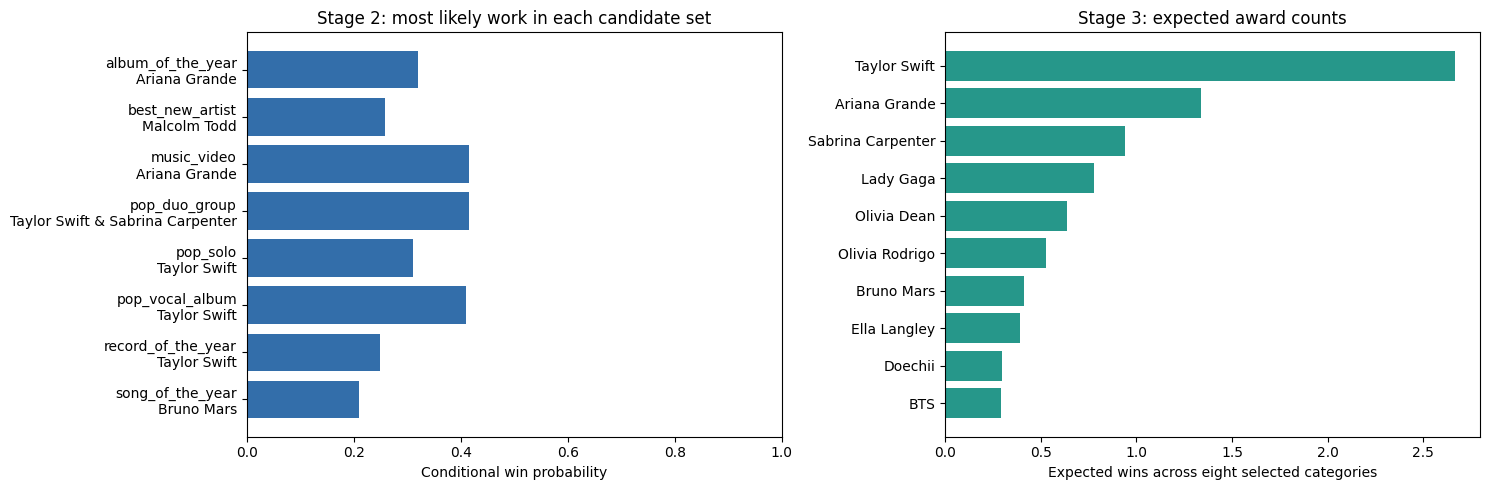

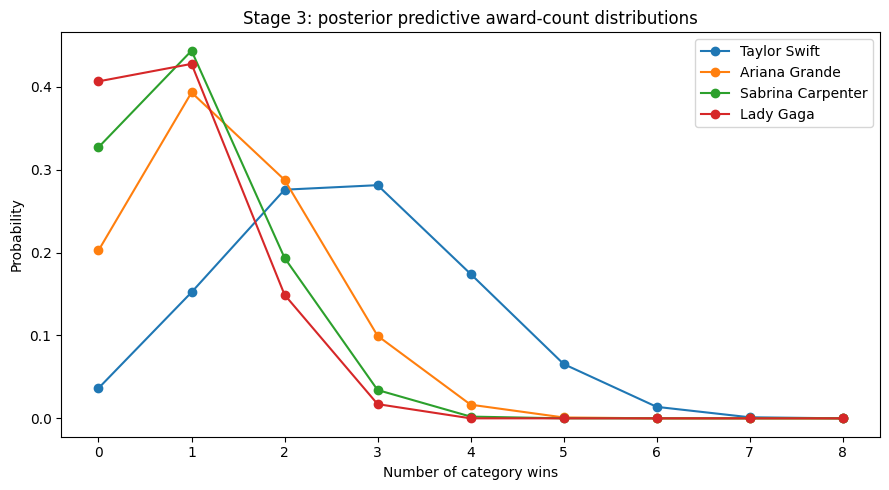

In [ ]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(15,5))
sw=slide_winners.copy();labels=sw['cat']+'\n'+sw['performer']
axes[0].barh(labels,sw.probability,color='#336EAA');axes[0].invert_yaxis();axes[0].set_xlim(0,1);axes[0].set_title('Stage 2: most likely work in each candidate set');axes[0].set_xlabel('Conditional win probability')
sc=slide_counts.head(10).iloc[::-1]
axes[1].barh(sc.artist,sc.expected_awards,color='#26978A');axes[1].set_xlabel('Expected wins across eight selected categories');axes[1].set_title('Stage 3: expected award counts')
fig.tight_layout();fig.savefig(OUTPUT/'PRESENTATION_forecasts_2027.png',dpi=180,bbox_inches='tight');plt.show()
fig2,ax=plt.subplots(figsize=(9,5))
for a in slide_counts.artist.head(4):
    q=count_pmf[count_pmf.model.eq('bayesian')&count_pmf.artist.eq(a)]
    ax.plot(q['count'],q.probability,marker='o',label=a)
ax.set(xlabel='Number of category wins',ylabel='Probability',xticks=range(9),title='Stage 3: posterior predictive award-count distributions');ax.legend();fig2.tight_layout();fig2.savefig(OUTPUT/'PRESENTATION_count_distributions_2027.png',dpi=180);plt.show()

## Optional evaluation: 2024 and 2025 only

Task A evaluates among official nominees. Task B uses the already frozen Stage 1 held-out shortlist/work sets. Task B reports winner-work coverage separately and conditional log scores only where the winning work is present. Unmatched works include catalog/version/identity gaps, so this is coverage of the complete construction pipeline, not only Stage 1 artist coverage.

For Task B count scores, a ceremony qualifies only if all eight winning works are in the constructed sets. The number of qualifying ceremonies is reported even if zero; no count accuracy is claimed in that case. Actual outcomes never select candidate works. Higher log score is better; negative log loss is reported separately. Two ceremonies do not support a strong significance claim. Keeping this cell off means no new backtest accuracy claim.

In [ ]:
RUN_BACKTESTS = True

In [ ]:
# Optional: two extra fits. Final 2027 outputs above remain available even if this is skipped.
def actual_counts(official):
    result={}
    for r in official[official.winner.eq(1)].itertuples():
        for a in set(r.artist_keys):result[a]=result.get(a,0)+1
    return result
if RUN_BACKTESTS:
    score_rows=[];coverage_rows=[];count_scores=[];qualifying=[];diagnostics=[final_diagnostics]
    for season in TEST_SEASONS:
        tm=history.season.lt(season).to_numpy();om=history.season.eq(season).to_numpy();cm=choices.season.eq(season).to_numpy()
        tr=history.loc[tm].reset_index(drop=True);off=history.loc[om].reset_index(drop=True);cand=choices.loc[cm].reset_index(drop=True)
        s=scaler_fit(X_HISTORY[tm]);b,d=fit_fold(tr,scaler_apply(X_HISTORY[tm],s),season,s);diagnostics.append(d)
        # Coverage checks use winner labels only after the candidate set has been frozen.
        cov=cand.groupby('cat').winner.sum().reindex(CATEGORIES,fill_value=0).eq(1)
        all_covered=bool(cov.all());qualifying.append(dict(season=season,all_eight_winners_covered=all_covered))
        for cat in CATEGORIES:
            coverage_rows.append(dict(season=season,cat=cat,K=int(cand['cat'].eq(cat).sum()),winner_work_covered=bool(cov[cat]),protocol='constructed pre-nomination shortlist'))
        for protocol,frame,raw in [('A_official_nominees',off,X_HISTORY[om]),('B_constructed_shortlist',cand,X_CHOICES[cm])]:
            for model,pred in [('bayesian',probabilities(frame,scaler_apply(raw,s),b)),('uniform',probabilities(frame,scaler_apply(raw,s)))]:
                for o in pred.values():
                    g,lp=o['frame'],o['logp'];wins=np.flatnonzero(g.winner.to_numpy()==1)
                    covered=len(wins)==1
                    ls=float(logsumexp(lp[:,wins[0]])-np.log(len(lp))) if covered else np.nan
                    score_rows.append(dict(season=season,cat=g['cat'].iloc[0],protocol=protocol,model=model,K=len(g),winner_covered=covered,log_score=ls,negative_log_loss=-ls))
                actual=actual_counts(off) if protocol.startswith('A') or all_covered else None
                pmf,cs=stage3(pred,model+'_'+protocol,season,actual=actual)
                pmf.to_csv(OUTPUT/f'backtest_count_pmf_{season}_{protocol}_{model}.csv',index=False)
                cs['protocol']=protocol;cs['all_eight_winners_covered']=all_covered;count_scores.append(cs)
    scores=pd.DataFrame(score_rows);coverage=pd.DataFrame(coverage_rows);qual=pd.DataFrame(qualifying)
    scores.to_csv(OUTPUT/'backtest_stage2_scores.csv',index=False);coverage.to_csv(OUTPUT/'backtest_shortlist_coverage.csv',index=False);qual.to_csv(OUTPUT/'backtest_stage3_qualifying_ceremonies.csv',index=False)
    pd.concat(count_scores,ignore_index=True).to_csv(OUTPUT/'backtest_stage3_count_scores.csv',index=False);pd.DataFrame(diagnostics).to_csv(OUTPUT/'mcmc_diagnostics.csv',index=False)
    print('Stage 2: higher log score is better; shortlist misses excluded only from CONDITIONAL score.');display(scores.groupby(['protocol','model']).agg(mean_log_score=('log_score','mean'),scored_events=('log_score','count')))
    print('Task B winner coverage:');display(coverage.groupby('season').winner_work_covered.mean())
    print('Stage 3 Task B qualifying ceremonies:',int(qual.all_eight_winners_covered.sum()),'of',len(qual));display(qual)
else:
    print('Backtests skipped by configuration. No new validation metrics are claimed.')

Fitting season 2024: 214 historical events, 2 chains


sample: 100%|██████████| 1500/1500 [00:06<00:00, 218.61it/s, 15 steps of size 3.04e-01. acc. prob=0.96]


,season,max_rhat,min_ess,divergences,depth_hits,cache_key
0,2024,1.002062,1449.698204,0,0,ed04c243f82ca470a28e21cfd70e49de4b90cc5787e429...


Fitting season 2025: 222 historical events, 2 chains


sample: 100%|██████████| 1500/1500 [00:06<00:00, 214.67it/s, 15 steps of size 3.18e-01. acc. prob=0.95]


,season,max_rhat,min_ess,divergences,depth_hits,cache_key
0,2025,1.000653,1371.325991,0,0,5789a0fb10425277e60a8fe6f4d6e6a01f5b8f46fd96a5...


... (3 outputs left out)

Task B winner coverage:


season
2024    0.375
2025    0.250
Name: winner_work_covered, dtype: float64

Stage 3 Task B qualifying ceremonies: 0 of 2


,season,all_eight_winners_covered
0,2024,False
1,2025,False


In [ ]:
comparison = []

for season in [2024, 2025]:
    # Загружаем уже обученную модель из кэша
    diagnostic = json.loads(
        (OUTPUT / f'diagnostics_{season}.json').read_text()
    )
    cache_file = (
        OUTPUT / 'posterior_cache'
        / f"{diagnostic['cache_key']}.npz"
    )

    with np.load(cache_file) as z:
        b = z['beta'].reshape(-1, len(FEATURES))

    train_mask = history.season.lt(season).to_numpy()
    test_mask = choices.season.eq(season).to_numpy()

    scale = scaler_fit(X_HISTORY[train_mask])
    test = choices.loc[test_mask].reset_index(drop=True)

    pred = probabilities(
        test,
        scaler_apply(X_CHOICES[test_mask], scale),
        b
    )
    table, _ = stage2_tables(pred, 'bayesian', season)

    # Самый вероятный вариант в каждой категории
    top = (
        table.sort_values(
            ['cat', 'probability', 'work_id'],
            ascending=[True, False, True]
        )
        .drop_duplicates('cat')
        .merge(test[['work_id', 'winner']], on='work_id')
    )

    actual = history[
        history.season.eq(season) & history.winner.eq(1)
    ][['cat', 'title', 'performer']].rename(columns={
        'title': 'actual_work',
        'performer': 'actual_artist'
    })

    result = top.merge(actual, on='cat')
    result['correct'] = result.winner.eq(1)
    result['winner_in_candidate_set'] = result['cat'].map(
        test.groupby('cat').winner.max().eq(1)
    )
    comparison.append(result)

comparison = pd.concat(comparison, ignore_index=True)

columns = [
    'ceremony_year', 'cat',
    'title', 'performer', 'probability',
    'actual_work', 'actual_artist',
    'correct', 'winner_in_candidate_set'
]

display(comparison[columns])

comparison[columns].to_csv(
    OUTPUT / 'PRESENTATION_backtest_predictions_vs_actual.csv',
    index=False
)

,ceremony_year,cat,title,performer,probability,actual_work,actual_artist,correct,winner_in_candidate_set
0,2025,album_of_the_year,THE TORTURED POETS DEPARTMENT,Taylor Swift,0.371989,COWBOY CARTER,Beyonce,False,True
1,2025,album_of_the_year,THE TORTURED POETS DEPARTMENT,Taylor Swift,0.371989,COWBOY CARTER,Beyonce,False,True
2,2025,best_new_artist,Teddy Swims,Teddy Swims,0.239749,Chappell Roan,Chappell Roan,False,True
3,2025,music_video,Fortnight,Taylor Swift & Post Malone,0.474446,Not Like Us,Kendrick Lamar,False,False
4,2025,pop_duo_group,Die With A Smile,Lady Gaga & Bruno Mars,0.410326,Die With A Smile,Lady Gaga and Bruno Mars,True,True
5,2025,pop_duo_group,Die With A Smile,Lady Gaga & Bruno Mars,0.410326,Die With A Smile,Lady Gaga and Bruno Mars,False,True
6,2025,pop_solo,Down Bad,Taylor Swift,0.380526,Espresso,Sabrina Carpenter,False,False
7,2025,pop_vocal_album,HIT ME HARD AND SOFT,Billie Eilish,0.301684,Short n' Sweet,Sabrina Carpenter,False,False
8,2025,record_of_the_year,LUNCH,Billie Eilish,0.331020,Not Like Us,Kendrick Lamar,False,False
9,2025,record_of_the_year,LUNCH,Billie Eilish,0.331020,Not Like Us,Kendrick Lamar,False,False


In [ ]:
metadata=dict(model_version=MODEL_VERSION,forecast_season=FORECAST_SEASON,ceremony_year=2027,backtests_run=RUN_BACKTESTS,test_seasons=TEST_SEASONS if RUN_BACKTESTS else [],settings=dict(warmup=WARMUP,samples=SAMPLES,chains=CHAINS,target_accept=TARGET_ACCEPT,max_tree_depth=MAX_TREE_DEPTH),features=FEATURES,final_diagnostics=final_diagnostics,stage1_manifest=json.loads((INPUT/'stage1_manifest.json').read_text()),input_hashes=INPUT_HASHES,selection_rule='One work per shortlisted artist: strongest available chart peak, then most chart weeks, then work_id; merge shared works; omit unknown/out-of-window releases.',date_rule='first release in Grammy window OR verified album availability in window; latter is a proxy, not proof of eligibility',conditioning='Each category winner belongs to constructed set. Count forecasts condition on this in all eight categories.',credit_rule='Every named performing act on winning work receives +1; band stays one act; does not reproduce legal songwriter/producer trophy credits.',dependence='Independent category outcomes conditional on one shared beta posterior draw. No additional shared voter/artist shocks.',limitations=['Curated and incomplete catalog; omitted artists and genre/submission uncertainties','Historical source identities including Silk Sonic remain limitations','Stage1 export explicitly original-data v4, not corrected-data refit','Stage1 information cutoff is September 30 proxy; historical publication vintages not fully audited','Model trained on official nominee sets and transferred to constructed work sets','Stage1 probabilities are selection inputs, not a modeled joint distribution of nominations'])
(OUTPUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2))
shutil = __import__('shutil')
shutil.copyfile(INPUT/'forecast_choices.csv',OUTPUT/'used_work_choices.csv');shutil.copyfile(INPUT/'omitted_artist_choices.csv',OUTPUT/'omitted_artist_choices.csv')
report='''# Presentation notes\n\nStage 2 tables show conditional win probabilities among the supplied candidate works. They do not represent unconditional Grammy win probabilities. Stage 3 counts cover eight selected categories and credit every named performing act of a winning collaboration. Baseline is 1/K per work.\n\nThe candidate catalog is incomplete; artists without dated works were omitted. Album availability dates are proxies. Genre, submission and all eligibility rules are not fully verified. Stage1 provenance is retained unchanged. Diagnostic summaries and actual computed forecasts are saved in this folder. No accuracy claim follows from future probability rankings.\n'''
(OUTPUT/'PRESENTATION_notes.md').write_text(report)
archive=ROOT/'stage23_results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUTPUT.rglob('*'):
        if p.is_file():z.write(p,p.relative_to(OUTPUT))
print('Download this archive and return it to Chat B:',archive)
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    from IPython.display import FileLink
    display(FileLink(str(archive)))

Download this archive and return it to Chat B: /kaggle/working/stage23_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json, shutil
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from scipy.special import logsumexp

if MODEL_VERSION != 'pooled-work-conditional-logit-stage23-v2':
    raise ValueError('Use the original Bayesian conditional-logit Stage 2/3 notebook.')
BT_YEARS = list(range(2018,2026))
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
BT23_OUT = Path(OUTPUT)/('expanded_stage23_'+stamp)
BT23_OUT.mkdir(parents=True,exist_ok=True)
stage2_rows, work_parts, count_parts, pmf_parts, diag_rows = [],[],[],[],[]
for season in BT_YEARS:
    tm = history.season.lt(season).to_numpy()
    om = history.season.eq(season).to_numpy()
    train=history.loc[tm].reset_index(drop=True)
    official=history.loc[om].reset_index(drop=True)
    if set(official.cat)!=set(CATEGORIES) or official.event_id.nunique()!=8:
        raise ValueError(f'{season}: expected exactly one official event per selected category.')
    s = scaler_fit(X_HISTORY[tm])
    beta,d = fit_fold(train,scaler_apply(X_HISTORY[tm],s),season,s)
    diag_rows.append(d)
    actual={}
    for r in official[official.winner.eq(1)].itertuples():
        for a in set(r.artist_keys): actual[a]=actual.get(a,0)+1
    for model,pred in [('bayesian',probabilities(official,scaler_apply(X_HISTORY[om],s),beta)),
                       ('uniform',probabilities(official,scaler_apply(X_HISTORY[om],s)))]:
        wt,_=stage2_tables(pred,model,season)
        wt['protocol']='A_official_nominees'
        work_parts.append(wt)
        for o in pred.values():
            g,lp=o['frame'],o['logp']
            win=np.flatnonzero(g.winner.to_numpy()==1)
            if len(win)!=1: raise ValueError('Official event must contain exactly one winner.')
            logp=logsumexp(lp,axis=0)-np.log(len(lp))
            top=int(np.lexsort((g.work_id.to_numpy(),-logp))[0])
            stage2_rows.append(dict(season=season,ceremony_year=season+1,cat=g['cat'].iloc[0],
                event_id=g.event_id.iloc[0],model=model,protocol='A_official_nominees',K=len(g),
                log_score=float(logp[win[0]]),log_loss=-float(logp[win[0]]),
                top1_correct=bool(top==win[0]),predicted_work=g.title.iloc[top],
                predicted_artist=g.performer.iloc[top],actual_work=g.title.iloc[win[0]],
                actual_artist=g.performer.iloc[win[0]],winner_covered=True))
        pm,cs=stage3(pred,model+'_expanded_official',season,actual=actual)
        # Normalize model labels for joining results from all notebooks.
        for table in [pm,cs]:
            table['model']=model
            table['protocol']='A_official_nominees'
        cs['absolute_error']=(cs.expected_awards-cs.actual_count).abs()
        count_parts.append(cs);pmf_parts.append(pm)
    pd.DataFrame(stage2_rows).to_csv(BT23_OUT/'stage2_scores_2018_2025.csv',index=False)
    pd.concat(count_parts,ignore_index=True).to_csv(BT23_OUT/'stage3_scores_2018_2025.csv',index=False)
    pd.concat(pmf_parts,ignore_index=True).to_csv(BT23_OUT/'stage3_pmfs_2018_2025.csv',index=False)
    pd.concat(work_parts,ignore_index=True).to_csv(BT23_OUT/'stage2_work_probabilities_2018_2025.csv',index=False)
    pd.DataFrame(diag_rows).to_csv(BT23_OUT/'mcmc_diagnostics.csv',index=False)
    print('Official-nominee Bayesian backtests complete:',season,flush=True)

bt2=pd.DataFrame(stage2_rows);bt3=pd.concat(count_parts,ignore_index=True)
if len(bt2)!=8*8*2: raise ValueError('Incomplete Stage 2 evaluation.')
display(bt2.groupby('model').agg(log_loss=('log_loss','mean'),top1_hits=('top1_correct','sum'),events=('top1_correct','size')))
display(bt3.groupby('model').agg(count_log_score=('count_log_score','mean'),
    mean_absolute_error=('absolute_error','mean'),coverage_90=('covered_90','mean')))
bt2.groupby(['season','model'],as_index=False).agg(log_loss=('log_loss','mean'),
    top1_hits=('top1_correct','sum')).to_csv(BT23_OUT/'stage2_yearly_scores.csv',index=False)
bt3.groupby(['season','model'],as_index=False).agg(count_log_score=('count_log_score','mean'),
    mean_absolute_error=('absolute_error','mean'),coverage_90=('covered_90','mean')).to_csv(BT23_OUT/'stage3_yearly_scores.csv',index=False)
(BT23_OUT/'run_metadata.json').write_text(json.dumps(dict(model_version=MODEL_VERSION,
    test_seasons=BT_YEARS,input_hashes=INPUT_HASHES,features=FEATURES,
    stage1_manifest=json.loads((INPUT/'stage1_manifest.json').read_text()),
    scope='Task A: official nominees only; not an end-to-end nomination forecast',
    count_convention='All named acts on a winning collaboration credited once; eight categories',
    limitations=['Retrospective data','Only eight dependent annual occasions']),indent=2))
BT23_ZIP=shutil.make_archive(str(BT23_OUT),'zip',root_dir=BT23_OUT)
print('Download from Kaggle Output:',BT23_ZIP)

Fitting season 2018: 166 historical events, 2 chains


sample: 100%|██████████| 1500/1500 [00:06<00:00, 233.41it/s, 15 steps of size 3.26e-01. acc. prob=0.96]


,season,max_rhat,min_ess,divergences,depth_hits,cache_key
0,2018,1.002094,1367.847656,0,0,c969cbf1f6fdfcfde3cdcc7706755e8596666f061d90a6...


Official-nominee Bayesian backtests complete: 2018
Fitting season 2019: 174 historical events, 2 chains


sample: 100%|██████████| 1500/1500 [00:06<00:00, 226.95it/s, 15 steps of size 3.17e-01. acc. prob=0.96]


,season,max_rhat,min_ess,divergences,depth_hits,cache_key
0,2019,1.001669,1324.161753,0,0,a5426c734f2ada733df2f27b501db59b5965ac9a86780e...


... (16 outputs left out)

Official-nominee Bayesian backtests complete: 2025


,log_loss,top1_hits,events
model,,,
bayesian,2.050758,12,64
uniform,1.894243,3,64


,count_log_score,mean_absolute_error,coverage_90
model,,,
bayesian,-0.641062,0.375837,0.947566
uniform,-0.594454,0.371888,0.973783


Download from Kaggle Output: /kaggle/working/stage23_results/20261101T150916188122/expanded_stage23_20261101T151030263430.zip
